# Model experiments

Central workspace for comparing architectures under a shared protocol. Architecture definitions live in `src/models/`; preparation, training, and evaluation are shared in `src/experiments.py`. Start by comparing saved models. Training is explicitly disabled by default. Character-level diagnostics belong to notebook 05.

The existing artifacts are historical single-seed experiments. Their split and class mapping are documented in the earlier notebooks, but not all have machine-readable provenance. New runs record both. The test set remains reserved for final evaluation.

In [3]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import tensorflow as tf

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models import MODELS
from src.experiments import DEFAULT_TRAINING, prepare_data, train_model, compare_models

## 1. Common data and training settings

In [4]:
training_settings = DEFAULT_TRAINING.copy()
frames, unique_char = prepare_data(split_seed=training_settings["split_seed"])
df_train = frames["train"]
df_valid = frames["validation"]
df_test = frames["test"]
BATCH_SIZE = training_settings["batch_size"]
SPLIT_SEED = training_settings["split_seed"]
TRAINING_SEED = training_settings["training_seed"]

display(pd.DataFrame([
    {"Split": name, "Images": len(df), "Writers": df.writer_id.nunique()}
    for name, df in frames.items()
]).set_index("Split"))

,Images,Writers
Split,,
train,47375,987
validation,10128,211
test,10223,213


## 2. Available architectures

To add an architecture, create a script with `NAME`, `ARTIFACT`, `CONFIG`, and `build_model(input_shape, num_classes, seed)`, then register it in `src/models/__init__.py`. Keep the training protocol common when comparing architectures.

In [5]:
display(pd.DataFrame([
    {"Key": key, "Name": definition.NAME, **definition.CONFIG}
    for key, definition in MODELS.items()
]).set_index("Key"))

,Name,filters,kernel_size,dense_units,dropout
Key,,,,,
baseline,Dense 128 (baseline),"[32, 64]",3,128,NaN
dense64,Dense 64,"[32, 64]",3,64,NaN
dropout20,Dense 128 + dropout 0.2,"[32, 64]",3,128,0.2
dropout30,Dense 128 + dropout 0.3,"[32, 64]",3,128,0.3
dropout40,Dense 128 + dropout 0.4,"[32, 64]",3,128,0.4
dropout50,Dense 128 + dropout 0.5,"[32, 64]",3,128,0.5


## 3. Optional training of one selected model

Choose a model key and a unique run name. Set `RUN_TRAINING = True` only when you want to launch a new experiment. Existing artifacts are never overwritten. Each run saves the model, history, classes, architecture and training settings, and validation fingerprint.

The common runner builds a fresh training dataset and does not iterate it for a preliminary prediction. Historical notebooks consumed one shuffled batch before training, so new runs may not reproduce their exact batch order. Compare new architectures under the common runner and use multiple seeds for stronger conclusions.

In [6]:
MODEL_KEY = "dropout20"
RUN_NAME = "dropout20_seed12_v2"
RUN_TRAINING = False

if RUN_TRAINING:
    model, history = train_model(
        MODEL_KEY, frames, unique_char,
        run_name=RUN_NAME, settings=training_settings,
    )
else:
    print("Training disabled. Saved models can be compared below.")

Training disabled. Saved models can be compared below.


### Optional series: three dropout rates

The controlled study compares baseline, dropout 0.2, and dropout 0.4 using the shared training settings. The planned series is listed below; unfinished runs are explicitly marked as pending. Leave the flag false to avoid training; the runner reuses completed matching runs, but interrupted unsaved runs restart from scratch. Change the prefix to create a fresh series. The CLI offers the same workflow.

In [7]:
RUN_DROPOUT_SERIES = False

if RUN_DROPOUT_SERIES:
    from src.run_experiments import run_series
    dropout_comparison = run_series(
        ["baseline", "dropout20", "dropout40"],
        prefix="dropout_study", seed=SPLIT_SEED,
    )

### Confirmation: fixed split, three training seeds

Compare dropout rates 0, 0.2, and 0.4 across training seeds 12, 23, and 34. These seeds are predefined arbitrary reproducible choices, not tuned hyperparameters. Keep the writer split at `SPLIT_SEED = 12`. Initialization, training shuffle, and dropout randomness change with the training seed; writer membership and labels do not.

This is nine separate fresh runs with a new prefix. Earlier single-seed artifacts remain unchanged. Training is disabled by default. Enable only `RUN_MULTISEED_STUDY` to launch this study; leave the other training flags false. Completed matching runs are reused, while interrupted unsaved runs restart from scratch. No final-test predictions are made.

In [8]:
from src.run_experiments import (
    seed_study_plan, run_seed_study, evaluate_seed_study,
)

MULTISEED_MODELS = ["baseline", "dropout20", "dropout40"]
TRAINING_SEEDS = [12, 23, 34]
STUDY_PREFIX = "dropout_multiseed"

study_plan = seed_study_plan(
    MULTISEED_MODELS, training_seeds=TRAINING_SEEDS,
    split_seed=SPLIT_SEED, prefix=STUDY_PREFIX,
)
study_plan["Saved"] = study_plan["Artifact"].map(Path.is_file)
display(study_plan.drop(columns="Artifact"))

,Run,Model key,Model,Split seed,Training seed,Saved
0,dropout_multiseed_baseline_split12_train12,baseline,Dense 128 (baseline),12,12,True
1,dropout_multiseed_dropout20_split12_train12,dropout20,Dense 128 + dropout 0.2,12,12,True
2,dropout_multiseed_dropout40_split12_train12,dropout40,Dense 128 + dropout 0.4,12,12,True
3,dropout_multiseed_baseline_split12_train23,baseline,Dense 128 (baseline),12,23,True
4,dropout_multiseed_dropout20_split12_train23,dropout20,Dense 128 + dropout 0.2,12,23,True
5,dropout_multiseed_dropout40_split12_train23,dropout40,Dense 128 + dropout 0.4,12,23,True
6,dropout_multiseed_baseline_split12_train34,baseline,Dense 128 (baseline),12,34,True
7,dropout_multiseed_dropout20_split12_train34,dropout20,Dense 128 + dropout 0.2,12,34,True
8,dropout_multiseed_dropout40_split12_train34,dropout40,Dense 128 + dropout 0.4,12,34,True


In [9]:
RUN_MULTISEED_STUDY = False

if RUN_MULTISEED_STUDY:
    seed_results, seed_summary = run_seed_study(
        MULTISEED_MODELS, training_seeds=TRAINING_SEEDS,
        split_seed=SPLIT_SEED, prefix=STUDY_PREFIX,
    )
else:
    print("Multi-seed training disabled. Run the next cell to inspect available results.")

Multi-seed training disabled. Run the next cell to inspect available results.


#### Evaluate saved runs without training

This cell evaluates only available saved runs and reports missing ones. Mean and sample standard deviation are exported to `reports/dropout_multiseed_summary.csv`, with individual runs in `reports/dropout_multiseed_runs.csv`. `Complete` must be true for all three models before interpreting the aggregate ranking. A standard deviation is unavailable with fewer than two runs and is not a confidence interval.

In [10]:
seed_results, seed_summary = evaluate_seed_study(
    MULTISEED_MODELS, training_seeds=TRAINING_SEEDS,
    split_seed=SPLIT_SEED, prefix=STUDY_PREFIX,
)
if not seed_results.empty:
    display(seed_results[[
        "Model", "Split seed", "Training seed", "Validation accuracy", "Validation loss",
    ]].style.format({"Validation accuracy": "{:.2%}", "Validation loss": "{:.4f}"}))
display(seed_summary.style.format({
    "Validation accuracy mean": "{:.2%}",
    "Validation accuracy std": "{:.2%}",
    "Validation loss mean": "{:.4f}",
    "Validation loss std": "{:.4f}",
}, na_rep="Not available"))
if not seed_summary["Complete"].all():
    print("Study incomplete: finish all planned runs before ranking the models.")

,Model,Split seed,Training seed,Validation accuracy,Validation loss
0,Dense 128 (baseline),12,12,93.35%,0.2458
1,Dense 128 + dropout 0.2,12,12,94.59%,0.2126
2,Dense 128 + dropout 0.4,12,12,94.95%,0.1878
3,Dense 128 (baseline),12,23,94.14%,0.2183
4,Dense 128 + dropout 0.2,12,23,94.65%,0.1944
5,Dense 128 + dropout 0.4,12,23,94.98%,0.1823
6,Dense 128 (baseline),12,34,93.53%,0.2275
7,Dense 128 + dropout 0.2,12,34,94.80%,0.1900
8,Dense 128 + dropout 0.4,12,34,95.17%,0.1722


,Runs,Expected runs,Complete,Validation accuracy mean,Validation accuracy std,Validation loss mean,Validation loss std
Model,,,,,,,
Dense 128 (baseline),3,3,True,93.67%,0.41%,0.2305,0.0140
Dense 128 + dropout 0.2,3,3,True,94.68%,0.11%,0.1990,0.0120
Dense 128 + dropout 0.4,3,3,True,95.04%,0.12%,0.1808,0.0079


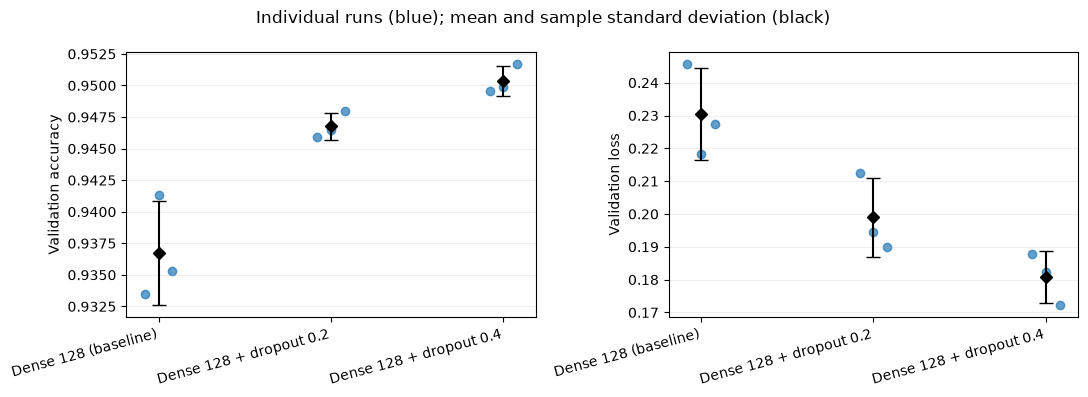

In [11]:
if not seed_results.empty:
    names = [MODELS[key].NAME for key in MULTISEED_MODELS]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axes, ["Validation accuracy", "Validation loss"]):
        for position, name in enumerate(names):
            values = seed_results.loc[seed_results["Model"].eq(name), metric]
            if values.empty:
                continue
            offsets = np.linspace(-0.08, 0.08, len(values)) if len(values) > 1 else [0]
            ax.scatter(position + np.asarray(offsets), values, color="tab:blue", alpha=0.7)
            if len(values) > 1:
                ax.errorbar(position, values.mean(), yerr=values.std(ddof=1),
                            fmt="D", color="black", capsize=5)
        ax.set_xticks(range(len(names)), names, rotation=15, ha="right")
        ax.set_ylabel(metric)
        ax.grid(axis="y", alpha=0.2)
    fig.suptitle("Individual runs (blue); mean and sample standard deviation (black)")
    fig.tight_layout()
    plt.show()

### Refine dropout: 0.3, 0.4, and 0.5

The first three-seed comparison favored 0.4 consistently. Compare its two neighbors using the same split seed 12, training seeds 12/23/34, architecture, learning rate, batch size, epoch budget, and EarlyStopping rule.

The three 0.4 models are reused from `dropout_multiseed`; only 0.3 and 0.5 require training (six new runs). Artifact names keep that prefix to identify the existing models. A separate report prefix, `dropout_refinement`, preserves the original 0/0.2/0.4 CSVs. No artifact is copied or overwritten. The test set remains untouched.

Run imports and common data preparation first. Set only `RUN_DROPOUT_REFINEMENT = True` to train. Leave every other training flag false. To inspect saved results without training, leave this flag false and run the evaluation cell.

In [12]:
from src.run_experiments import seed_study_plan, run_seed_study, evaluate_seed_study

REFINEMENT_MODELS = ["dropout30", "dropout40", "dropout50"]
REFINEMENT_SEEDS = [12, 23, 34]
REFINEMENT_ARTIFACT_PREFIX = "dropout_multiseed"
REFINEMENT_REPORT_PREFIX = "dropout_refinement"

refinement_plan = seed_study_plan(
    REFINEMENT_MODELS, training_seeds=REFINEMENT_SEEDS,
    split_seed=SPLIT_SEED, prefix=REFINEMENT_ARTIFACT_PREFIX,
)
refinement_plan["Saved"] = refinement_plan["Artifact"].map(Path.is_file)
display(refinement_plan.drop(columns="Artifact"))
print("New runs required:", int((~refinement_plan["Saved"]).sum()))

,Run,Model key,Model,Split seed,Training seed,Saved
0,dropout_multiseed_dropout30_split12_train12,dropout30,Dense 128 + dropout 0.3,12,12,False
1,dropout_multiseed_dropout40_split12_train12,dropout40,Dense 128 + dropout 0.4,12,12,True
2,dropout_multiseed_dropout50_split12_train12,dropout50,Dense 128 + dropout 0.5,12,12,False
3,dropout_multiseed_dropout30_split12_train23,dropout30,Dense 128 + dropout 0.3,12,23,False
4,dropout_multiseed_dropout40_split12_train23,dropout40,Dense 128 + dropout 0.4,12,23,True
5,dropout_multiseed_dropout50_split12_train23,dropout50,Dense 128 + dropout 0.5,12,23,False
6,dropout_multiseed_dropout30_split12_train34,dropout30,Dense 128 + dropout 0.3,12,34,False
7,dropout_multiseed_dropout40_split12_train34,dropout40,Dense 128 + dropout 0.4,12,34,True
8,dropout_multiseed_dropout50_split12_train34,dropout50,Dense 128 + dropout 0.5,12,34,False


New runs required: 6


In [18]:
RUN_DROPOUT_REFINEMENT = True

if RUN_DROPOUT_REFINEMENT:
    refinement_results, refinement_summary = run_seed_study(
        REFINEMENT_MODELS, training_seeds=REFINEMENT_SEEDS,
        split_seed=SPLIT_SEED, prefix=REFINEMENT_ARTIFACT_PREFIX,
        report_prefix=REFINEMENT_REPORT_PREFIX,
    )
else:
    print("Refinement training disabled. Saved results can be evaluated below.")

Training dropout_multiseed_dropout30_split12_train12
Epoch 1/10
1481/1481 - 39s - 26ms/step - accuracy: 0.6667 - loss: 1.1975 - val_accuracy: 0.8905 - val_loss: 0.3964
Epoch 2/10
1481/1481 - 39s - 26ms/step - accuracy: 0.8754 - loss: 0.4258 - val_accuracy: 0.9319 - val_loss: 0.2524
Epoch 3/10
1481/1481 - 42s - 28ms/step - accuracy: 0.9181 - loss: 0.2808 - val_accuracy: 0.9386 - val_loss: 0.2176
Epoch 4/10
1481/1481 - 41s - 28ms/step - accuracy: 0.9375 - loss: 0.2043 - val_accuracy: 0.9414 - val_loss: 0.2170
Epoch 5/10
1481/1481 - 41s - 28ms/step - accuracy: 0.9501 - loss: 0.1597 - val_accuracy: 0.9492 - val_loss: 0.2003
Epoch 6/10
1481/1481 - 41s - 28ms/step - accuracy: 0.9585 - loss: 0.1321 - val_accuracy: 0.9485 - val_loss: 0.2076
Epoch 7/10
1481/1481 - 41s - 28ms/step - accuracy: 0.9667 - loss: 0.1029 - val_accuracy: 0.9508 - val_loss: 0.1996
Epoch 8/10
1481/1481 - 41s - 28ms/step - accuracy: 0.9716 - loss: 0.0873 - val_accuracy: 0.9496 - val_loss: 0.2243
Epoch 9/10
1481/1481 - 44s 

#### Evaluate refinement without training

The next cells report individual runs and mean/sample standard deviation. Missing runs are explicit. Results are exported to `reports/dropout_refinement_runs.csv` and `reports/dropout_refinement_summary.csv`. Standard deviation is not a confidence interval.

In [19]:
refinement_results, refinement_summary = evaluate_seed_study(
    REFINEMENT_MODELS, training_seeds=REFINEMENT_SEEDS,
    split_seed=SPLIT_SEED, prefix=REFINEMENT_ARTIFACT_PREFIX,
    report_prefix=REFINEMENT_REPORT_PREFIX,
)
if not refinement_results.empty:
    display(refinement_results[[
        "Model", "Split seed", "Training seed", "Validation accuracy", "Validation loss",
    ]].style.format({"Validation accuracy": "{:.2%}", "Validation loss": "{:.4f}"}))
display(refinement_summary.style.format({
    "Validation accuracy mean": "{:.2%}", "Validation accuracy std": "{:.2%}",
    "Validation loss mean": "{:.4f}", "Validation loss std": "{:.4f}",
}, na_rep="Not available"))
if not refinement_summary["Complete"].all():
    print("Refinement incomplete: finish all planned runs before ranking rates.")

,Model,Split seed,Training seed,Validation accuracy,Validation loss
0,Dense 128 + dropout 0.3,12,12,95.08%,0.1996
1,Dense 128 + dropout 0.4,12,12,94.95%,0.1878
2,Dense 128 + dropout 0.5,12,12,94.92%,0.1824
3,Dense 128 + dropout 0.3,12,23,95.15%,0.1828
4,Dense 128 + dropout 0.4,12,23,94.98%,0.1823
5,Dense 128 + dropout 0.5,12,23,95.27%,0.1839
6,Dense 128 + dropout 0.3,12,34,95.05%,0.1897
7,Dense 128 + dropout 0.4,12,34,95.17%,0.1722
8,Dense 128 + dropout 0.5,12,34,95.25%,0.1862


,Runs,Expected runs,Complete,Validation accuracy mean,Validation accuracy std,Validation loss mean,Validation loss std
Model,,,,,,,
Dense 128 + dropout 0.3,3,3,True,95.10%,0.05%,0.1907,0.0085
Dense 128 + dropout 0.4,3,3,True,95.04%,0.12%,0.1808,0.0079
Dense 128 + dropout 0.5,3,3,True,95.15%,0.19%,0.1842,0.0019


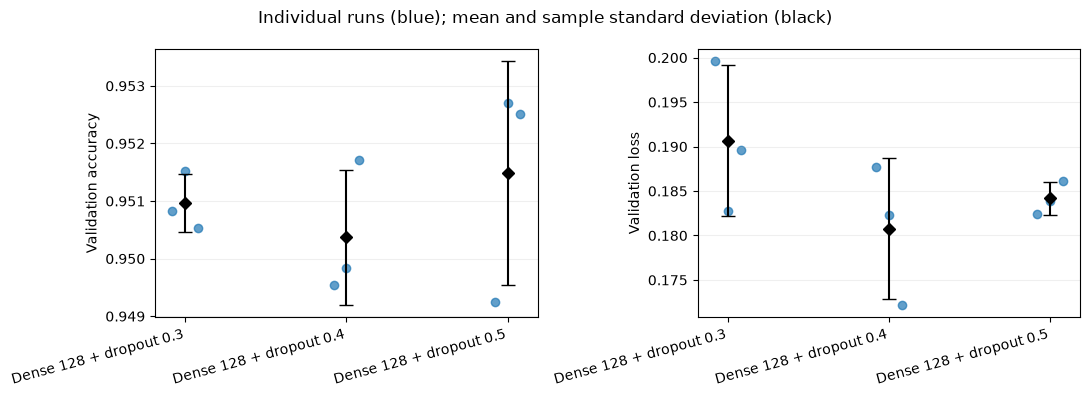

In [20]:
if not refinement_results.empty:
    names = [MODELS[key].NAME for key in REFINEMENT_MODELS]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axes, ["Validation accuracy", "Validation loss"]):
        for position, name in enumerate(names):
            values = refinement_results.loc[refinement_results["Model"].eq(name), metric]
            if values.empty:
                continue
            offsets = np.linspace(-0.08, 0.08, len(values)) if len(values) > 1 else [0]
            ax.scatter(position + np.asarray(offsets), values, color="tab:blue", alpha=0.7)
            if len(values) > 1:
                ax.errorbar(position, values.mean(), yerr=values.std(ddof=1),
                            fmt="D", color="black", capsize=5)
        ax.set_xticks(range(len(names)), names, rotation=15, ha="right")
        ax.set_ylabel(metric)
        ax.grid(axis="y", alpha=0.2)
    fig.suptitle("Individual runs (blue); mean and sample standard deviation (black)")
    fig.tight_layout()
    plt.show()

## 4. Global validation comparison

Select saved artifacts explicitly. Primary measures are validation accuracy and loss. Parameter count describes model size; character-specific confusions are diagnostics, not selection criteria. Models are evaluated after loading their saved weights. New-run provenance is checked; missing historical provenance is shown in the table.

To compare a new run, add its saved `.keras` path to `artifacts`. A model file must be available locally; these notebooks do not train missing models automatically.

In [21]:
artifacts = {
    "Dense 128 (historical baseline)": project_root / "models" / "katakana_baseline.keras",
    "Dense 64 (historical)": project_root / "models" / "katakana_dense64.keras",
    "Baseline (common protocol)": project_root / "models" / "dropout_study_baseline_seed12.keras",
    "Dropout 0.2 (common protocol)": project_root / "models" / "dropout_study_dropout20_seed12.keras",
    "Dropout 0.4 (common protocol)": project_root / "models" / "dropout_study_dropout40_seed12.keras",
}

available_artifacts = {name: path for name, path in artifacts.items() if path.is_file()}
pending_artifacts = {name: path for name, path in artifacts.items() if not path.is_file()}
for name in pending_artifacts:
    print(f"Not trained/saved yet: {name}")

comparison = compare_models(available_artifacts, df_valid, unique_char, batch_size=BATCH_SIZE)
display(comparison.style.format({
    "Parameters": "{:,.0f}",
    "Validation accuracy": "{:.2%}",
    "Validation loss": "{:.4f}",
}))
reports_dir = project_root / "reports"
reports_dir.mkdir(exist_ok=True)
comparison.to_csv(reports_dir / "model_comparison.csv")

,Parameters,Validation accuracy,Validation loss,Validation errors,Class mapping,Split provenance
Run,,,,,,
Dense 128 (historical baseline),"6,677,040",93.51%,0.2439,657,Historical assumption,Historical assumption
Dense 64 (historical),"3,347,952",93.09%,0.2517,700,Saved,Historical assumption
Baseline (common protocol),"6,677,040",93.35%,0.2458,674,Saved,Recorded
Dropout 0.2 (common protocol),"6,677,040",94.59%,0.2126,548,Saved,Recorded
Dropout 0.4 (common protocol),"6,677,040",94.95%,0.1878,511,Saved,Recorded


## 5. Learning curves for available histories

Training histories are optional for historical artifacts. Their absence is reported rather than reconstructed. The curves include epochs before EarlyStopping restored the best weights. Their last epoch is not necessarily the saved model's selected epoch.

No saved history for Dense 128 (historical baseline).


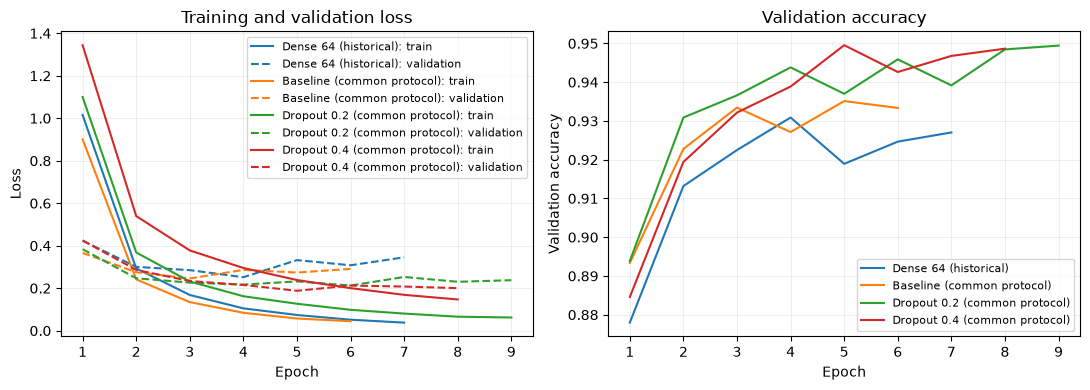

In [22]:
available_histories = {}
for name, path in available_artifacts.items():
    history_path = path.with_name(path.stem + "_history.json")
    if history_path.exists():
        available_histories[name] = json.loads(history_path.read_text())
    else:
        print(f"No saved history for {name}.")

if available_histories:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, values in available_histories.items():
        epochs = range(1, len(values["loss"]) + 1)
        line, = axes[0].plot(epochs, values["loss"], label=f"{name}: train")
        axes[0].plot(epochs, values["val_loss"], linestyle="--",
                     color=line.get_color(), label=f"{name}: validation")
        axes[1].plot(epochs, values["val_accuracy"], label=name)
    axes[0].set(xlabel="Epoch", ylabel="Loss", title="Training and validation loss")
    axes[1].set(xlabel="Epoch", ylabel="Validation accuracy", title="Validation accuracy")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

## 6. Dropout conclusion

Dropout improved generalization in the three-seed study: mean validation accuracy rose from 93.67% without dropout to 95.04% at 0.4, and mean loss fell from 0.2305 to 0.1808. The finer comparison is complete:

| Rate | Mean validation accuracy | Accuracy sample std (points) | Mean validation loss |
|---|---:|---:|---:|
| 0.3 | 95.10% | 0.05 | 0.1907 |
| 0.4 | 95.04% | 0.12 | 0.1808 |
| 0.5 | 95.15% | 0.19 | 0.1842 |

Rate 0.5 has the highest mean accuracy; 0.4 has the lowest mean loss. The accuracy difference between them is only 0.11 percentage points, about 11 validation images on average, and the ranking is not identical for every seed. No configuration dominates both criteria. Standard deviation describes variation across the three training seeds, not uncertainty across unseen writer populations.

**Retain dropout 0.4 as the working configuration and conclude rate tuning.** This preserves the clear regularization gain and lowest mean loss, without claiming that 0.4 is universally optimal or maximizes accuracy. The user reported about 50 minutes for refinement; its small marginal gains do not justify further fine searches for this project.

For future experiments, agree on a compute budget first. Start with one exploratory run per motivated change and repeat only when the benefit justifies the cost. Favor concrete recognition or computational-cost improvements. No next experiment is launched here. Keep the test set untouched until the final configuration is frozen. Character confusions remain optional diagnostics in notebook 05.

See `reports/dropout_refinement.md` for the recorded conclusion.